# Comptage de mots : Python, pseudo-MapReduce, Hadoop MapReduce et PySpark

**Cours :** Fondements et Application de Big Data — 13/10/26

# Partie 1 : Hadoop MapReduce

On implémente les trois méthodes du document *Comptage des mots*, on les teste, puis on les compare sur les mêmes fichiers, de tailles différentes.

## 1. Environnement

Python 3, Java 17 et Apache Hadoop 3.4.2 en mode pseudo-distribué : HDFS et YARN tournent comme dans le document, mais sur une seule machine.

Installation, dans le dossier du notebook :

```bash
curl -LO https://dlcdn.apache.org/hadoop/common/hadoop-3.4.2/hadoop-3.4.2-lean.tar.gz
tar -xzf hadoop-3.4.2-lean.tar.gz && mv hadoop-3.4.2 hadoop
```

Propriétés principales, dans `hadoop/etc/hadoop/` :

| Fichier | Propriété | Valeur |
|---|---|---|
| `core-site.xml` | `fs.defaultFS` | `hdfs://localhost:9000` |
| `hdfs-site.xml` | `dfs.replication` | `1` |
| `mapred-site.xml` | `mapreduce.framework.name` | `yarn` |
| `yarn-site.xml` | `yarn.nodemanager.aux-services` | `mapreduce_shuffle` |

Démarrage du cluster :

```bash
hadoop/bin/hdfs namenode -format
hadoop/bin/hdfs --daemon start namenode
hadoop/bin/hdfs --daemon start datanode
hadoop/bin/yarn --daemon start resourcemanager
hadoop/bin/yarn --daemon start nodemanager
```

In [1]:
import random, subprocess, time
from collections import defaultdict

HADOOP = "hadoop/bin/hadoop"
HDFS = "hadoop/bin/hdfs"
JAR = "hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.2.jar"
DOSSIER = "/user/maxime/wordcount"   # dossier de travail sur HDFS

## 2. Génération des fichiers

Un fichier de N lignes, avec un mot par ligne tiré au hasard dans une liste de 15 mots (donc avec répétition), puis un fichier de m × N lignes obtenu en recopiant ces N lignes m fois.

In [2]:
MOTS = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne", "livre",
        "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]

def generer_fichier(nom, n):
    with open(nom, "w", encoding="utf-8") as f:
        for _ in range(n):
            f.write(random.choice(MOTS) + "\n")

def dupliquer_fichier(source, destination, m):
    with open(source, encoding="utf-8") as f:
        contenu = f.read()
    with open(destination, "w", encoding="utf-8") as f:
        for _ in range(m):
            f.write(contenu)

random.seed(0)
N = 1000
generer_fichier("mots.txt", N)

## 3. Méthode 1 : Python simple

On lit tout le fichier et on compte avec un dictionnaire.

In [3]:
def compter_python(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

## 4. Méthode 2 : pseudo-MapReduce en Python

Les trois étapes de MapReduce dans un seul programme Python : **map** transforme chaque ligne en paires `(mot, 1)`, **shuffle** regroupe les valeurs par mot, **reduce** les additionne.

In [4]:
def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    return {mot: sum(valeurs) for mot, valeurs in grouped_data.items()}

def compter_pseudo_mapreduce(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    return reducer(shuffle(mapped))

## 5. Méthode 3 : Hadoop MapReduce

Mêmes étapes que dans le document : copie du fichier sur HDFS, lancement du job `wordcount` fourni avec Hadoop, lecture du résultat sur HDFS. Elles sont dans trois fonctions séparées pour pouvoir mesurer le temps du job seul.

In [5]:
def hdfs(*arguments):
    return subprocess.run([HDFS, "dfs", *arguments], check=True, capture_output=True, text=True).stdout

def envoyer_sur_hdfs(fichier):
    hdfs("-mkdir", "-p", DOSSIER + "/input")
    hdfs("-put", "-f", fichier, DOSSIER + "/input/")
    hdfs("-rm", "-r", "-f", DOSSIER + "/output")   # Hadoop refuse un dossier de sortie existant

def lancer_job_hadoop(fichier):
    subprocess.run([HADOOP, "jar", JAR, "wordcount", DOSSIER + "/input/" + fichier, DOSSIER + "/output"],
                   check=True, capture_output=True)

def lire_resultat_hadoop():
    compteur = {}
    for ligne in hdfs("-cat", DOSSIER + "/output/part-r-00000").splitlines():
        mot, nb = ligne.split()
        compteur[mot] = int(nb)
    return compteur

## 6. Tests

Sur `mots.txt` (N = 1000 lignes), les trois méthodes doivent donner le même résultat, et le total des occurrences doit valoir N.

In [6]:
r1 = compter_python("mots.txt")
r2 = compter_pseudo_mapreduce("mots.txt")
envoyer_sur_hdfs("mots.txt")
lancer_job_hadoop("mots.txt")
r3 = lire_resultat_hadoop()

for mot, nb in sorted(r1.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

assert r1 == r2 == r3
assert sum(r1.values()) == N
print("\nLes trois méthodes donnent le même résultat, total =", sum(r1.values()))

chien : 83
jardin : 76
voiture : 76
chat : 72
lune : 69
mer : 68
oiseau : 66
soleil : 66
livre : 64
route : 63
montagne : 62
maison : 62
arbre : 61
fleur : 57
ciel : 55

Les trois méthodes donnent le même résultat, total = 1000


## 7. Comparaison des temps d'exécution

On fait varier m de 1 à 10 000, soit de 1000 à 10 millions de lignes (63 Mo). Pour chaque fichier on mesure le temps du comptage seul (pour Hadoop : la commande `hadoop jar`, sans la copie sur HDFS) et on vérifie que les résultats sont identiques.

On s'arrête à 10 millions de lignes à cause de la machine : un essai à 50 millions de lignes a rempli le disque et fait échouer le job Hadoop.

In [7]:
def chronometrer(fonction, fichier):
    debut = time.perf_counter()
    resultat = fonction(fichier)
    return resultat, time.perf_counter() - debut

M = [1, 100, 1000, 5000, 10000]
temps = {"Python simple": [], "Pseudo-MapReduce": [], "Hadoop MapReduce": []}

print(f"{'m':>6} {'lignes':>10} {'Python (s)':>11} {'Pseudo-MR (s)':>14} {'Hadoop (s)':>11}")
for m in M:
    dupliquer_fichier("mots.txt", "gros.txt", m)
    envoyer_sur_hdfs("gros.txt")
    a, t1 = chronometrer(compter_python, "gros.txt")
    b, t2 = chronometrer(compter_pseudo_mapreduce, "gros.txt")
    _, t3 = chronometrer(lancer_job_hadoop, "gros.txt")
    assert a == b == lire_resultat_hadoop() and sum(a.values()) == m * N
    temps["Python simple"].append(t1)
    temps["Pseudo-MapReduce"].append(t2)
    temps["Hadoop MapReduce"].append(t3)
    print(f"{m:>6} {m * N:>10} {t1:>11.4f} {t2:>14.4f} {t3:>11.1f}")

     m     lignes  Python (s)  Pseudo-MR (s)  Hadoop (s)


     1       1000      0.0002         0.0004        13.1


   100     100000      0.0086         0.0421        14.1


  1000    1000000      0.0858         0.3008        14.5


  5000    5000000      0.4511         1.6323        14.1


 10000   10000000      1.0018         3.4009        16.0


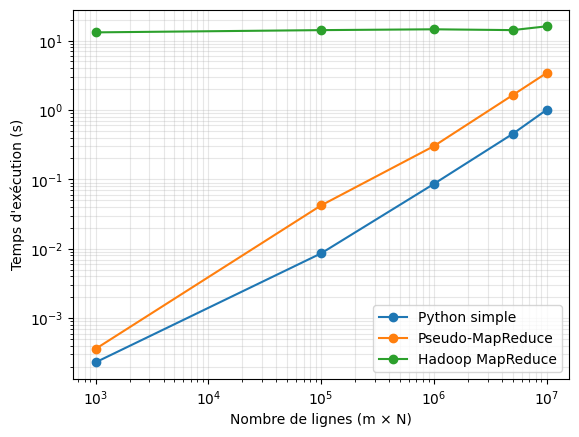

In [8]:
import matplotlib.pyplot as plt

lignes = [m * N for m in M]
for methode, valeurs in temps.items():
    plt.plot(lignes, valeurs, marker="o", label=methode)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Nombre de lignes (m × N)")
plt.ylabel("Temps d'exécution (s)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

## 8. Analyse

- **Python simple** est le plus rapide sur toutes les tailles : 1 s pour 10 millions de lignes, avec un temps proportionnel à la taille du fichier.
- **Pseudo-MapReduce** est 3 à 5 fois plus lent dès 100 000 lignes, car il construit puis regroupe toutes les paires `(mot, 1)` en mémoire.
- **Hadoop MapReduce** a un coût fixe d'environ 13 s même pour 1000 lignes (envoi du job à YARN, démarrage des conteneurs), proche des 12 s du document. Son temps augmente ensuite très peu : 16 s pour un fichier 10 000 fois plus gros.

Hadoop reste donc le plus lent, mais l'écart avec Python simple passe d'un facteur de plusieurs dizaines de milliers sur 1000 lignes à 16 sur 10 millions de lignes.

Limites : chaque temps n'est mesuré qu'une fois, et Hadoop tourne sur une seule machine avec des fichiers de 63 Mo au plus. On n'atteint pas les volumes de plusieurs gigaoctets où le document annonce que Hadoop devient plus performant.

## 9. Conclusion

Les trois méthodes donnent les mêmes comptages sur tous les fichiers. Tant que le fichier tient en mémoire, le dictionnaire Python est le plus simple et le plus rapide. Hadoop paie un coût de démarrage élevé mais son temps dépend peu de la taille : il n'est utile que pour des données qui dépassent une seule machine, ce que ce TP sur un seul poste ne permet pas de mesurer.

# Partie 2 : PySpark

On reprend le même exemple, le comptage d'occurrences de mots dans un fichier, avec PySpark.

## 1. Installation

```bash
pip install pyspark
```

PySpark 4.0.4 contient Spark et utilise le Java déjà installé. Spark tourne ici en mode local (`local[*]`), sur tous les cœurs de la machine, sans cluster.

In [9]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.master("local[*]").appName("wordcount").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

## 2. Comptage de mots avec PySpark

On retrouve les étapes de MapReduce : `flatMap` découpe chaque ligne en mots, `map` produit les paires `(mot, 1)`, et `reduceByKey` regroupe les paires par mot (shuffle) puis additionne les valeurs (reduce).

In [10]:
def compter_pyspark(fichier):
    lignes = spark.sparkContext.textFile(fichier)
    comptes = (lignes.flatMap(lambda ligne: ligne.split())
                     .map(lambda mot: (mot, 1))
                     .reduceByKey(lambda a, b: a + b))
    return dict(comptes.collect())

## 3. Test

Sur le même fichier `mots.txt`, PySpark doit donner le même résultat que les trois méthodes de la partie 1.

In [11]:
r4 = compter_pyspark("mots.txt")

for mot, nb in sorted(r4.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

assert r4 == r1
print("\nPySpark donne le même résultat que la partie 1, total =", sum(r4.values()))
spark.stop()

chien : 83
jardin : 76
voiture : 76
chat : 72
lune : 69
mer : 68
oiseau : 66
soleil : 66
livre : 64
route : 63
montagne : 62
maison : 62
arbre : 61
fleur : 57
ciel : 55

PySpark donne le même résultat que la partie 1, total = 1000


## 4. Conclusion

PySpark donne les mêmes comptages que les trois méthodes de la partie 1. Le programme suit le même modèle map / shuffle / reduce que Hadoop MapReduce, mais il s'écrit en quelques lignes de Python, sans fichier JAR ni copie préalable sur HDFS.